In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score,cross_val_predict
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import shap
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc,precision_score, recall_score, f1_score
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor


In [11]:
df=pd.read_csv('vehicles.csv')
df.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN


In [12]:
print(df.shape)
print(df.isnull().sum())
print(df.info())

(426880, 26)
id                   0
url                  0
region               0
region_url           0
price                0
year              1205
manufacturer     17646
model             5277
condition       174104
cylinders       177678
fuel              3013
odometer          4400
title_status      8242
transmission      2556
VIN             161042
drive           130567
size            306361
type             92858
paint_color     130203
image_url           68
description         70
county          426880
state                0
lat               6549
long              6549
posting_date        68
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 

In [13]:
df.isnull().sum()/len(df)*100

id                0.000000
url               0.000000
region            0.000000
region_url        0.000000
price             0.000000
year              0.282281
manufacturer      4.133714
model             1.236179
condition        40.785232
cylinders        41.622470
fuel              0.705819
odometer          1.030735
title_status      1.930753
transmission      0.598763
VIN              37.725356
drive            30.586347
size             71.767476
type             21.752717
paint_color      30.501078
image_url         0.015930
description       0.016398
county          100.000000
state             0.000000
lat               1.534155
long              1.534155
posting_date      0.015930
dtype: float64

In [14]:
df.describe()

,id,price,year,odometer,county,lat,long
count,4.268800e+05,4.268800e+05,425675.000000,4.224800e+05,0.0,420331.000000,420331.000000
mean,7.311487e+09,7.519903e+04,2011.235191,9.804333e+04,NaN,38.493940,-94.748599
std,4.473170e+06,1.218228e+07,9.452120,2.138815e+05,NaN,5.841533,18.365462
min,7.207408e+09,0.000000e+00,1900.000000,0.000000e+00,NaN,-84.122245,-159.827728
25%,7.308143e+09,5.900000e+03,2008.000000,3.770400e+04,NaN,34.601900,-111.939847
50%,7.312621e+09,1.395000e+04,2013.000000,8.554800e+04,NaN,39.150100,-88.432600
75%,7.315254e+09,2.648575e+04,2017.000000,1.335425e+05,NaN,42.398900,-80.832039
max,7.317101e+09,3.736929e+09,2022.000000,1.000000e+07,NaN,82.390818,173.885502


In [15]:
print(df["price"].value_counts().head(20))

price
0        32895
6995      3169
7995      3129
9995      2867
8995      2837
4500      2778
5995      2727
3500      2716
29990     2705
6500      2594
5500      2584
10995     2390
7500      2351
25990     2320
27990     2228
2500      2204
4995      2190
11995     2112
26990     2112
12995     2109
Name: count, dtype: int64


In [16]:
(df["price"] <= 0).sum()

np.int64(32895)

In [17]:
print(df["price"].quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]))

0.00    0.000000e+00
0.01    0.000000e+00
0.05    0.000000e+00
0.25    5.900000e+03
0.50    1.395000e+04
0.75    2.648575e+04
0.95    4.450000e+04
0.99    6.699500e+04
1.00    3.736929e+09
Name: price, dtype: float64


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df["id"].duplicated().sum()

np.int64(0)

In [20]:
df[df["price"] == 0].head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
10,7218893038,https://elpaso.craigslist.org/ctd/d/el-paso-20...,el paso,https://elpaso.craigslist.org,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,tx,NaN,NaN,NaN
11,7218325704,https://elpaso.craigslist.org/ctd/d/el-paso-20...,el paso,https://elpaso.craigslist.org,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,tx,NaN,NaN,NaN
12,7217788283,https://elpaso.craigslist.org/ctd/d/el-paso-20...,el paso,https://elpaso.craigslist.org,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,tx,NaN,NaN,NaN
13,7217147606,https://elpaso.craigslist.org/ctd/d/el-paso-20...,el paso,https://elpaso.craigslist.org,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,tx,NaN,NaN,NaN
14,7209027818,https://elpaso.craigslist.org/ctd/d/el-paso-20...,el paso,https://elpaso.craigslist.org,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,tx,NaN,NaN,NaN


In [21]:
print(df[df["price"] == 0]["condition"].value_counts(dropna=False))

condition
NaN          22715
excellent     6542
good          2301
like new      1118
new            173
fair            40
salvage          6
Name: count, dtype: int64


In [22]:
df.nlargest(20, "price")[["price", "year", "manufacturer", "model", "condition", "odometer"]]

,price,year,manufacturer,model,condition,odometer
318592,3736928711,2007.0,toyota,tundra,excellent,164000.0
356716,3736928711,1999.0,toyota,4runner,fair,211000.0
91576,3024942282,2000.0,mercedes-benz,benz e320,NaN,100000.0
257840,3024942282,2000.0,mercedes-benz,benz s430,NaN,100000.0
37410,3009548743,2021.0,chevrolet,NaN,NaN,1000.0
184704,1410065407,1989.0,jeep,wrangler,NaN,103000.0
153082,1234567890,2006.0,volvo,vnl,fair,200000.0
29386,1111111111,1999.0,ford,f350 super duty lariat,good,149000.0
37409,1111111111,2020.0,jeep,NaN,NaN,1000.0
280,987654321,1960.0,chevrolet,NaN,NaN,999999.0


In [23]:
print((df["price"] > 100000).sum())
print(df[df["price"] > 100000]["price"].describe())

655
count    6.550000e+02
mean     3.776890e+07
std      3.089394e+08
min      1.009950e+05
25%      1.129985e+05
50%      1.298880e+05
75%      1.635400e+05
max      3.736929e+09
Name: price, dtype: float64


In [24]:
df[(df["price"] > 100000) & (df["price"] < 1000000)][
    ["price", "year", "manufacturer", "model", "condition", "odometer"]
].head(20)

,price,year,manufacturer,model,condition,odometer
1727,130000,2019.0,chevrolet,corvette,like new,5000.0
2922,140000,2015.0,jeep,renegade,like new,49658.0
4797,104000,2018.0,dodge,NaN,NaN,483.0
4826,104900,2020.0,bmw,m805i,excellent,9000.0
5003,145000,2014.0,NaN,freightliner m2 106,like new,17094.0
7109,116000,2019.0,ford,f350 diesels powerstroke,like new,24000.0
7628,145000,2014.0,NaN,freightliner m2 106,like new,17094.0
8005,122995,2016.0,nissan,gt-r,good,9527.0
8495,213000,1933.0,ford,2 dr victoria,NaN,999999.0
8579,112900,1967.0,NaN,oldsmobile cutlass 442 W30,like new,32086.0


In [25]:
print(df["odometer"].describe())

count    4.224800e+05
mean     9.804333e+04
std      2.138815e+05
min      0.000000e+00
25%      3.770400e+04
50%      8.554800e+04
75%      1.335425e+05
max      1.000000e+07
Name: odometer, dtype: float64


In [26]:
print((df["odometer"] <= 0).sum())
print(df["odometer"].quantile([0, .01, .05, .25, .5, .75, .95, .99, 1]))


1965
0.00           0.0
0.01           2.0
0.05        6318.0
0.25       37704.0
0.50       85548.0
0.75      133542.5
0.95      204000.0
0.99      280000.0
1.00    10000000.0
Name: odometer, dtype: float64


In [27]:
df[df["price"] > 100000][
    ["price", "year", "manufacturer", "model", "condition", "odometer"]
].sort_values("price", ascending=False).head(30)

,price,year,manufacturer,model,condition,odometer
318592,3736928711,2007.0,toyota,tundra,excellent,164000.0
356716,3736928711,1999.0,toyota,4runner,fair,211000.0
91576,3024942282,2000.0,mercedes-benz,benz e320,NaN,100000.0
257840,3024942282,2000.0,mercedes-benz,benz s430,NaN,100000.0
37410,3009548743,2021.0,chevrolet,NaN,NaN,1000.0
184704,1410065407,1989.0,jeep,wrangler,NaN,103000.0
153082,1234567890,2006.0,volvo,vnl,fair,200000.0
37409,1111111111,2020.0,jeep,NaN,NaN,1000.0
29386,1111111111,1999.0,ford,f350 super duty lariat,good,149000.0
122470,987654321,1960.0,chevrolet,NaN,NaN,9999999.0


In [28]:
df.nlargest(30, "odometer")[
    ["price", "year", "manufacturer", "model", "condition", "odometer"]
]

,price,year,manufacturer,model,condition,odometer
9218,4000,1975.0,ford,f250,NaN,10000000.0
23100,15000,1957.0,chevrolet,nomad,NaN,10000000.0
28738,20000,1951.0,chevrolet,coe,good,10000000.0
34717,13,1962.0,chevrolet,impala,NaN,10000000.0
44280,16000,1975.0,porsche,914,good,10000000.0
67001,4350,1974.0,chevrolet,NaN,NaN,10000000.0
67003,7800,2007.0,toyota,NaN,NaN,10000000.0
81327,15000,1973.0,chevrolet,corvette,good,10000000.0
103798,6500,1978.0,NaN,1978 van,good,10000000.0
105059,500,2010.0,chevrolet,colorado,NaN,10000000.0


In [29]:
print(df["year"].describe())
print(df["year"].value_counts().sort_index().head(20))
print(df["year"].value_counts().sort_index().tail(20))

count    425675.000000
mean       2011.235191
std           9.452120
min        1900.000000
25%        2008.000000
50%        2013.000000
75%        2017.000000
max        2022.000000
Name: year, dtype: float64
year
1900.0    12
1901.0     3
1902.0     1
1903.0    12
1905.0     1
1909.0     1
1910.0     2
1913.0     2
1915.0     1
1916.0     2
1918.0     1
1920.0     2
1921.0     2
1922.0     3
1923.0    36
1924.0     9
1925.0     8
1926.0    16
1927.0    37
1928.0    38
Name: count, dtype: int64
year
2003.0     7151
2004.0     8971
2005.0    10622
2006.0    12763
2007.0    14873
2008.0    17150
2009.0    12185
2010.0    15829
2011.0    20341
2012.0    23898
2013.0    30794
2014.0    30283
2015.0    31538
2016.0    30434
2017.0    36420
2018.0    36369
2019.0    25375
2020.0    19298
2021.0     2396
2022.0      133
Name: count, dtype: int64


In [30]:
print((df["year"] < 1950).sum())
print(df[df["year"] < 1950][
    ["price", "year", "manufacturer", "model", "condition", "odometer"]
].sort_values("year").head(30))

1213
          price    year manufacturer                model  condition  \
398032      500  1900.0        dodge              rampage    salvage   
154138       75  1900.0          NaN          any and all        NaN   
95914         1  1900.0         ford          power wagon        NaN   
96564         1  1900.0         ford          power wagon        NaN   
94319         1  1900.0         ford          power wagon        NaN   
44754         1  1900.0          NaN                  All       good   
29955         1  1900.0          NaN                  All       fair   
269472      998  1900.0          NaN                  any        NaN   
126977        1  1900.0          NaN    The earth is flat       good   
123023     4500  1900.0          NaN    cushman white van  excellent   
42454     38250  1900.0        acura                  rdx        new   
32544         1  1900.0          NaN                  All       fair   
277762     4000  1901.0          NaN          olds type r  

In [31]:
print("Price > 100k:", (df["price"] > 100000).sum())
print("Price > 200k:", (df["price"] > 200000).sum())
print("Price > 500k:", (df["price"] > 500000).sum())
print("Price > 1M:", (df["price"] > 1_000_000).sum())
print("Price > 10M:", (df["price"] > 10_000_000).sum())

Price > 100k: 655
Price > 200k: 124
Price > 500k: 68
Price > 1M: 53
Price > 10M: 30


In [32]:
print("Odometer > 300k:", (df["odometer"] > 300000).sum())
print("Odometer > 500k:", (df["odometer"] > 500000).sum())
print("Odometer > 1M:", (df["odometer"] > 1_000_000).sum())
print("Odometer > 5M:", (df["odometer"] > 5_000_000).sum())

Odometer > 300k: 3032
Odometer > 500k: 1386
Odometer > 1M: 576
Odometer > 5M: 185


In [33]:
df[df["price"] > 1_000_000][
    ["price", "year", "manufacturer", "model", "condition", "odometer"]
].sort_values("price", ascending=False)

,price,year,manufacturer,model,condition,odometer
318592,3736928711,2007.0,toyota,tundra,excellent,164000.0
356716,3736928711,1999.0,toyota,4runner,fair,211000.0
257840,3024942282,2000.0,mercedes-benz,benz s430,NaN,100000.0
91576,3024942282,2000.0,mercedes-benz,benz e320,NaN,100000.0
37410,3009548743,2021.0,chevrolet,NaN,NaN,1000.0
184704,1410065407,1989.0,jeep,wrangler,NaN,103000.0
153082,1234567890,2006.0,volvo,vnl,fair,200000.0
29386,1111111111,1999.0,ford,f350 super duty lariat,good,149000.0
37409,1111111111,2020.0,jeep,NaN,NaN,1000.0
280,987654321,1960.0,chevrolet,NaN,NaN,999999.0


In [34]:
# Supprimer les prix invalides
df = df[(df["price"] > 0) & (df["price"] <= 1_000_000)].copy()

# Transformer les années suspectes en valeurs manquantes
df.loc[df["year"] < 1950, "year"] = np.nan

# Transformer les kilométrages manifestement aberrants en valeurs manquantes
df.loc[df["odometer"] > 1_000_000, "odometer"] = np.nan
print(df.shape)


(393932, 26)


In [35]:
df.describe()

,id,price,year,odometer,county,lat,long
count,3.939320e+05,393932.000000,391594.000000,391180.000000,0.0,390443.000000,390443.000000
mean,7.311481e+09,18933.765206,2011.230106,93795.765318,NaN,38.514114,-94.448127
std,4.471929e+06,16282.069500,8.727156,72167.586723,NaN,5.874988,18.194843
min,7.207408e+09,1.000000,1950.000000,0.000000,NaN,-84.122245,-159.827728
25%,7.308132e+09,7000.000000,2008.000000,37907.000000,NaN,34.620000,-111.236250
50%,7.312626e+09,15000.000000,2013.000000,86995.000000,NaN,39.254962,-88.049143
75%,7.315250e+09,27590.000000,2017.000000,135078.000000,NaN,42.418751,-80.832039
max,7.317101e+09,1000000.000000,2022.000000,1000000.000000,NaN,82.390818,173.885502


In [36]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": df.isnull().mean() * 100
})

missing = missing.sort_values("missing_percent", ascending=False)

print(missing)

              missing_count  missing_percent
county               393932       100.000000
size                 282899        71.814171
cylinders            160380        40.712610
VIN                  152114        38.614279
condition            151361        38.423129
drive                120224        30.518973
paint_color          117116        29.730004
type                  85900        21.805794
manufacturer          16180         4.107308
title_status           7734         1.963283
model                  4678         1.187515
long                   3489         0.885686
lat                    3489         0.885686
odometer               2752         0.698598
fuel                   2594         0.658489
year                   2338         0.593503
transmission           1823         0.462770
description              64         0.016246
posting_date             62         0.015739
image_url                62         0.015739
region_url                0         0.000000
url       

In [37]:
df = df.drop(columns=[
        "id",
        "url",
        "region_url",
        "image_url",
        "county"
    ])

In [38]:
print(df.shape)
print(df.columns.tolist())

(393932, 21)
['region', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'description', 'state', 'lat', 'long', 'posting_date']


EDA

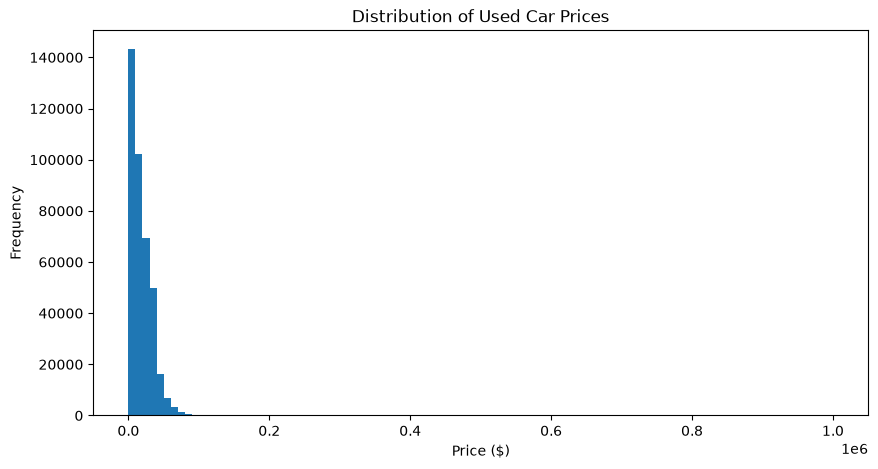

In [39]:

plt.figure(figsize=(10, 5))
plt.hist(df["price"], bins=100)
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Used Car Prices")
plt.show()

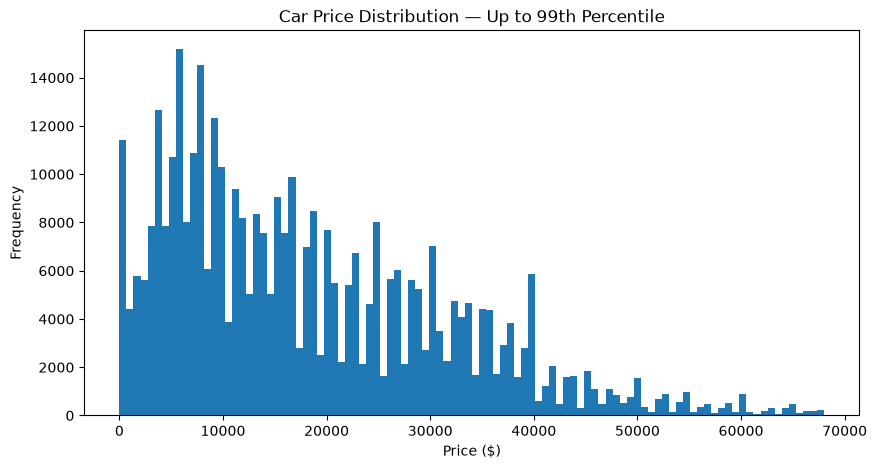

99th percentile: 68000.0


In [40]:
price_99 = df["price"].quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(df.loc[df["price"] <= price_99, "price"], bins=100)
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.title("Car Price Distribution — Up to 99th Percentile")
plt.show()

print("99th percentile:", price_99)

Price distribution: The target variable price is strongly right-skewed. Most used vehicles are concentrated in the lower and middle price ranges, while a small number of high-priced observations create a long right tail. The 99th percentile is around $67,000, indicating that extreme prices represent a small portion of the dataset. The distribution also shows several local peaks, likely related to common pricing practices in vehicle listings.

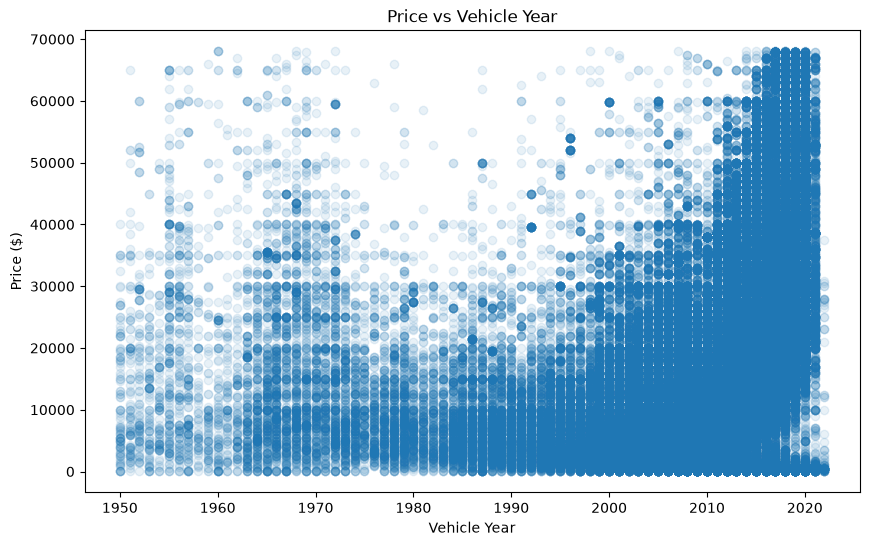

In [41]:
price_year = df[
    df["year"].notna() &
    (df["price"] <= df["price"].quantile(0.99))
]

plt.figure(figsize=(10, 6))

plt.scatter(
    price_year["year"],
    price_year["price"],
    alpha=0.1
)

plt.xlabel("Vehicle Year")
plt.ylabel("Price ($)")
plt.title("Price vs Vehicle Year")
plt.show()

Price vs Vehicle Year: The scatter plot shows a positive overall relationship between vehicle year and price. Newer vehicles tend to have higher prices, although substantial variability remains within each year. This indicates that year is likely to be an important predictive feature, but it cannot explain vehicle price on its own.

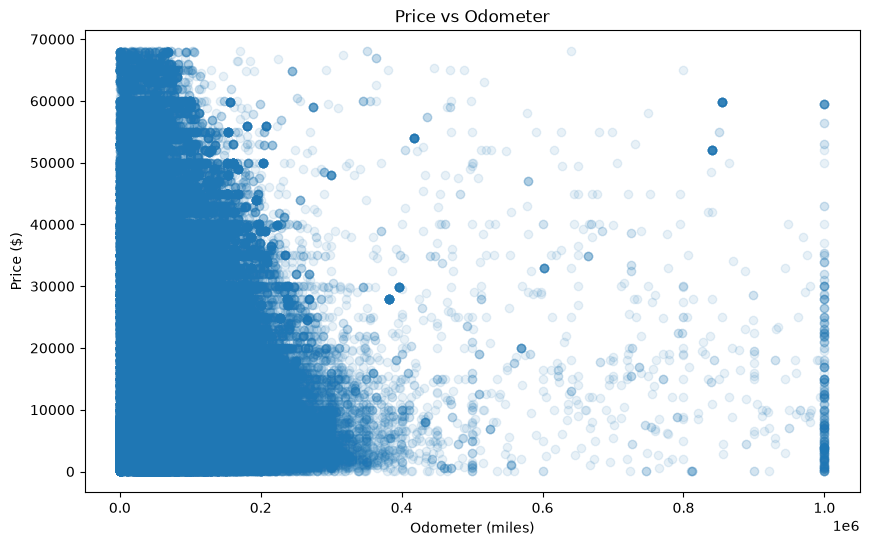

In [42]:
price_odo = df[
    df["odometer"].notna() &
    (df["price"] <= df["price"].quantile(0.99))
]

plt.figure(figsize=(10, 6))

plt.scatter(
    price_odo["odometer"],
    price_odo["price"],
    alpha=0.1
)

plt.xlabel("Odometer (miles)")
plt.ylabel("Price ($)")
plt.title("Price vs Odometer")
plt.show()

Price vs Odometer: The scatter plot shows an overall negative relationship between mileage and vehicle price. Vehicles with higher mileage tend to have lower prices, although the relationship presents substantial variability. Low-mileage vehicles cover a wide range of prices, suggesting that other factors such as vehicle year, manufacturer, model, and condition also strongly influence price.

In [43]:
print(df["manufacturer"].value_counts().head(20))

manufacturer
ford             64852
chevrolet        50615
toyota           31598
honda            19867
jeep             17458
nissan           17394
ram              16463
gmc              15430
bmw              13744
dodge            12367
mercedes-benz    10460
hyundai           9374
subaru            8986
volkswagen        8898
lexus             7741
kia               7547
audi              7180
cadillac          6591
acura             5707
chrysler          5656
Name: count, dtype: int64


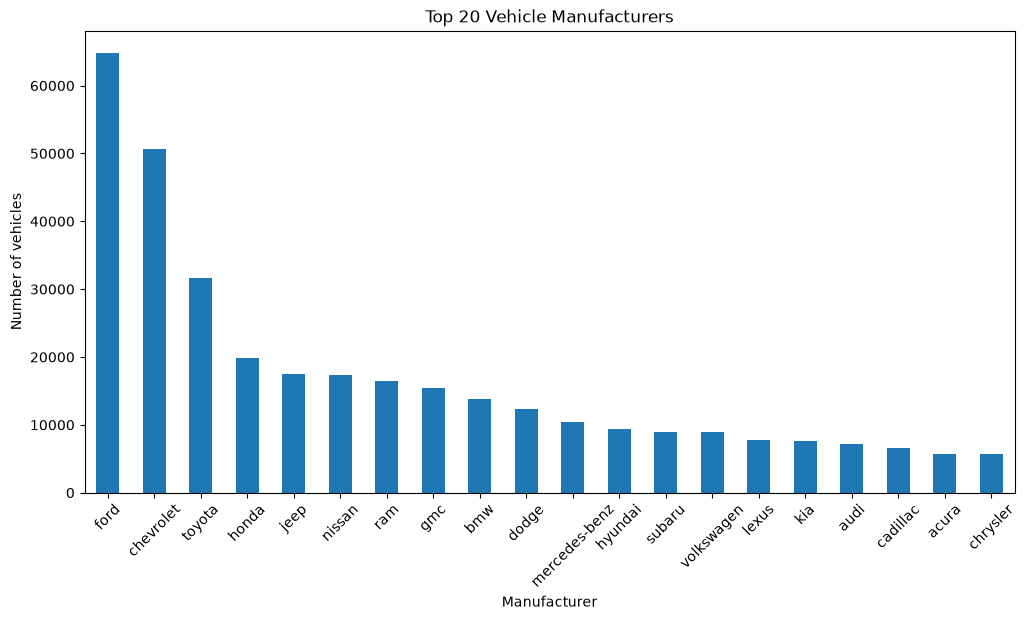

In [44]:
plt.figure(figsize=(12, 6))

df["manufacturer"].value_counts().head(20).plot(kind="bar")

plt.xlabel("Manufacturer")
plt.ylabel("Number of vehicles")
plt.title("Top 20 Vehicle Manufacturers")
plt.xticks(rotation=45)

plt.show()

In [45]:
manufacturer_stats = (
    df.groupby("manufacturer")["price"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print(manufacturer_stats.head(20))

               count          mean   median
manufacturer                               
ford           64852  21025.885000  16995.0
chevrolet      50615  19946.755665  15990.0
toyota         31598  17073.527217  13825.0
honda          19867  11510.079781   8995.0
jeep           17458  19666.487456  17999.0
nissan         17394  12876.385823   9999.0
ram            16463  29860.486971  29988.0
gmc            15430  25074.909851  23990.0
bmw            13744  20343.299913  17995.0
dodge          12367  15973.337430  11500.0
mercedes-benz  10460  22307.752581  18995.0
hyundai         9374  11822.043845  10500.0
subaru          8986  13795.024705  11500.0
volkswagen      8898  13166.912565  11888.0
lexus           7741  20344.975068  19988.0
kia             7547  12419.726779  11500.0
audi            7180  24865.228273  24674.5
cadillac        6591  20507.205128  16995.0
acura           5707  20785.118977  19590.0
chrysler        5656  11135.327263   7995.0


<Figure size 1400x700 with 0 Axes>

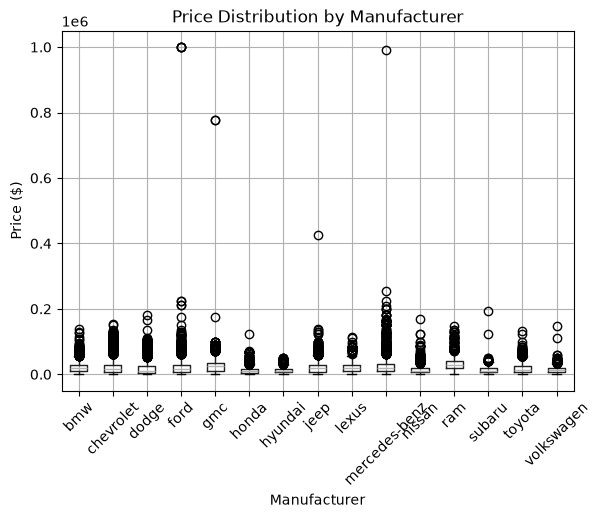

In [46]:
top_manufacturers = (
    df["manufacturer"]
    .value_counts()
    .head(15)
    .index
)

df_top_manufacturers = df[
    df["manufacturer"].isin(top_manufacturers)
]

plt.figure(figsize=(14, 7))

df_top_manufacturers.boxplot(
    column="price",
    by="manufacturer",
    rot=45
)

plt.xlabel("Manufacturer")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Manufacturer")
plt.suptitle("")

plt.show()

<Figure size 1400x700 with 0 Axes>

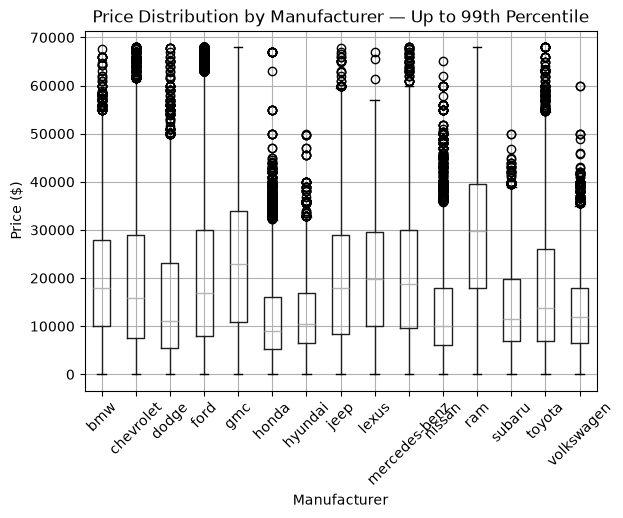

In [47]:
price_99 = df["price"].quantile(0.99)

df_boxplot = df[
    (df["manufacturer"].isin(top_manufacturers)) &
    (df["price"] <= price_99)
]

plt.figure(figsize=(14, 7))

df_boxplot.boxplot(
    column="price",
    by="manufacturer",
    rot=45
)

plt.xlabel("Manufacturer")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Manufacturer — Up to 99th Percentile")
plt.suptitle("")

plt.show()

Price by Manufacturer: Vehicle prices vary considerably across manufacturers. The median price ranges from approximately $9,000 for Honda to nearly $30,000 for Ram among the most represented manufacturers. The distributions also show substantial variability and numerous high-price observations. Therefore, manufacturer is likely to be an informative categorical feature for vehicle price prediction, although its relationship with price should be considered alongside other vehicle characteristics.

condition

condition
NaN          151361
good         119142
excellent     94924
like new      20055
fair           6723
new            1132
salvage         595
Name: count, dtype: int64
            count          mean   median
condition                               
good       119142  20977.004725  20590.0
new          1132  27272.732332  20000.0
NaN        151361  20079.145189  15887.0
like new    20055  19273.539417  14900.0
excellent   94924  15518.516687  11987.0
fair         6723   4094.010561   2800.0
salvage       595   3641.892437   1800.0


<Figure size 1000x600 with 0 Axes>

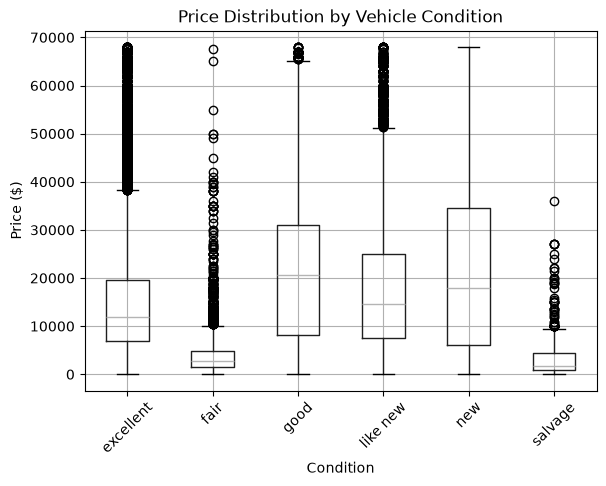

In [48]:
print(df["condition"].value_counts(dropna=False))
condition_stats = (
    df.groupby("condition", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print(condition_stats)
price_99 = df["price"].quantile(0.99)

condition_box = df[
    (df["price"] <= price_99)
]

plt.figure(figsize=(10, 6))

condition_box.boxplot(
    column="price",
    by="condition",
    rot=45
)

plt.xlabel("Condition")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Vehicle Condition")
plt.suptitle("")

plt.show()

Price by Vehicle Condition: Vehicle condition is associated with substantial differences in price distributions. Vehicles classified as good have a median price of approximately $20,590, while fair and salvage vehicles have considerably lower median prices. However, approximately 38% of observations have a missing condition value. These missing values will be retained and treated as an explicit unknown category during preprocessing rather than removing a large portion of the dataset.

fuel

fuel
gas         330399
other        28109
diesel       26318
hybrid        4886
NaN           2594
electric      1626
Name: count, dtype: int64
           count          mean   median
fuel                                   
diesel     26318  33733.482787  31990.0
other      28109  27999.961400  27590.0
electric    1626  25739.802583  24990.0
NaN         2594  20597.744410  17479.0
gas       330399  16988.830608  13500.0
hybrid      4886  15430.038477  12950.0


<Figure size 1000x600 with 0 Axes>

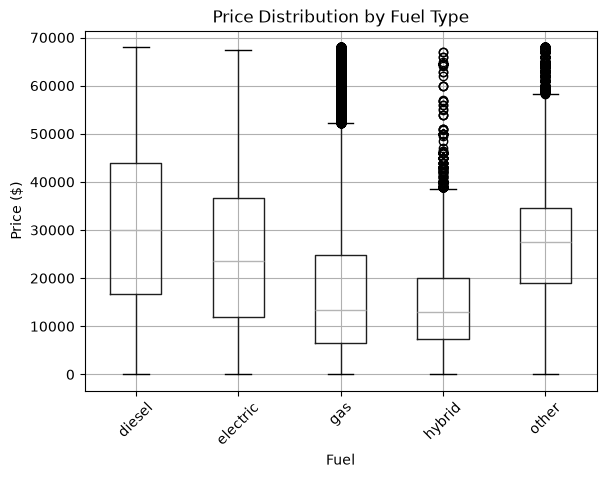

In [49]:
print(df["fuel"].value_counts(dropna=False))
fuel_stats = (
    df.groupby("fuel", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print(fuel_stats)
price_99 = df["price"].quantile(0.99)

fuel_box = df[df["price"] <= price_99]

plt.figure(figsize=(10, 6))

fuel_box.boxplot(
    column="price",
    by="fuel",
    rot=45
)

plt.xlabel("Fuel")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Fuel Type")
plt.suptitle("")

plt.show()

Price by Fuel Type: Fuel type is associated with differences in vehicle price distributions. Diesel vehicles have the highest median price among the main fuel categories, while gasoline vehicles dominate the dataset. Electric and hybrid vehicles have substantially fewer observations, so their distributions should be interpreted with caution. fuel will therefore be retained as a categorical predictive feature.

tranmision

transmission
automatic    306780
other         61477
manual        23852
NaN            1823
Name: count, dtype: int64
               count          mean   median
transmission                               
other          61477  28091.640305  28590.0
NaN             1823  20400.163467  14991.0
automatic     306780  17393.591701  12995.0
manual         23852  15027.279222   9999.0


<Figure size 1000x600 with 0 Axes>

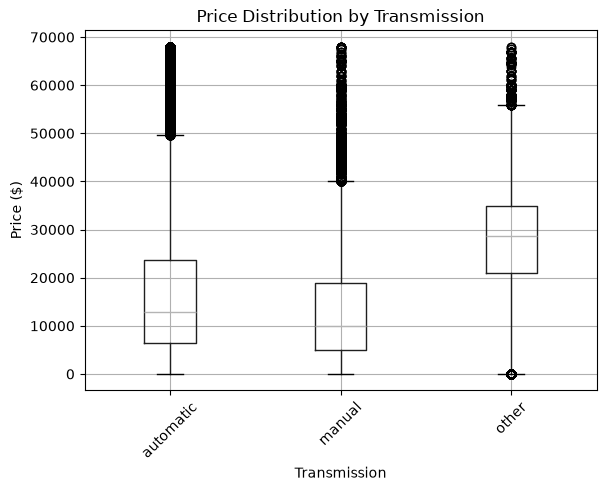

In [50]:
print(df["transmission"].value_counts(dropna=False))
transmission_stats = (
    df.groupby("transmission", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print(transmission_stats)
price_99 = df["price"].quantile(0.99)

transmission_box = df[df["price"] <= price_99]

plt.figure(figsize=(10, 6))

transmission_box.boxplot(
    column="price",
    by="transmission",
    rot=45
)

plt.xlabel("Transmission")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Transmission")
plt.suptitle("")

plt.show()

Price by Transmission: Transmission type is associated with differences in vehicle price distributions. Automatic transmission is by far the most common category, while manual vehicles have a lower median price in this dataset. The other category shows a substantially higher median price, although this category may contain heterogeneous transmission types. Therefore, transmission will be retained as a categorical feature.

type

type
NaN            85900
sedan          80318
SUV            70595
pickup         41368
truck          30627
other          19873
coupe          18213
hatchback      15917
wagon          10064
van             7974
convertible     7439
mini-van        4552
offroad          593
bus              499
Name: count, dtype: int64
             count          mean   median
type                                     
NaN          85900  15744.998219  10000.0
sedan        80318  14148.995493  10995.0
SUV          70595  17588.652100  14900.0
pickup       41368  28674.106483  27999.0
truck        30627  27019.958860  24995.0
other        19873  27528.844160  27990.0
coupe        18213  23070.216713  19990.0
hatchback    15917  14999.946786  14590.0
wagon        10064  14180.028120  12983.5
van           7974  18746.423000  16500.0
convertible   7439  20784.817180  15900.0
mini-van      4552   9787.889499   7400.0
offroad        593  16239.753794  12800.0
bus            499  14614.436874  11500.0


<Figure size 1400x700 with 0 Axes>

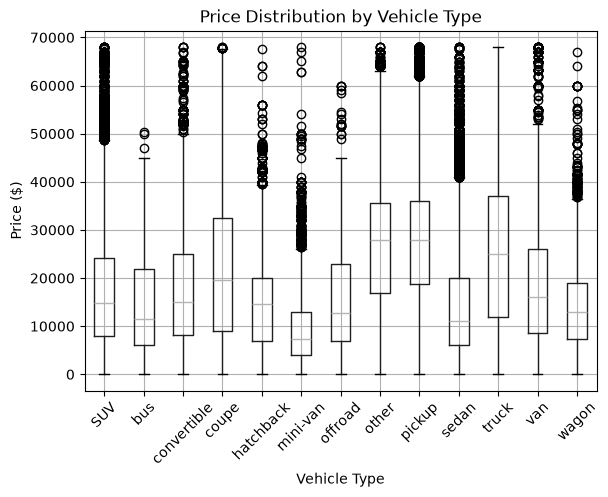

In [51]:
print(df["type"].value_counts(dropna=False))
type_stats = (
    df.groupby("type", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print(type_stats)
price_99 = df["price"].quantile(0.99)

type_box = df[df["price"] <= price_99]

plt.figure(figsize=(14, 7))

type_box.boxplot(
    column="price",
    by="type",
    rot=45
)

plt.xlabel("Vehicle Type")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Vehicle Type")
plt.suptitle("")

plt.show()

drive

        count          mean   median
drive                               
4wd    120656  23444.012697  19999.0
rwd     55377  21071.137566  18990.0
NaN    120224  18531.750957  14995.0
fwd     97675  12645.380978  10200.0


<Figure size 1000x600 with 0 Axes>

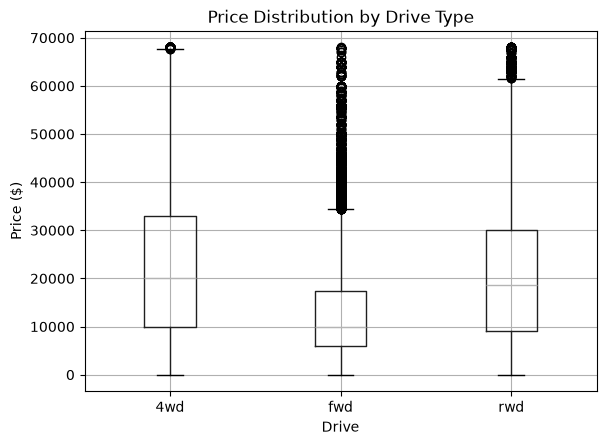

In [52]:
drive_stats = (
    df.groupby("drive", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("median", ascending=False)
)

print(drive_stats)
plt.figure(figsize=(10, 6))

df[df["price"] <= price_99].boxplot(
    column="price",
    by="drive"
)

plt.xlabel("Drive")
plt.ylabel("Price ($)")
plt.title("Price Distribution by Drive Type")
plt.suptitle("")

plt.show()

paint_color

In [53]:
paint_stats = (
    df.groupby("paint_color", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .sort_values("count", ascending=False)
)

print(paint_stats)
print(df["size"].value_counts(dropna=False))

              count          mean   median
paint_color                               
NaN          117116  17493.842874  12995.0
white         72858  22568.039515  19990.0
black         58499  21844.268603  18988.0
silver        40074  16801.598618  13350.5
blue          29461  17236.890975  13900.0
red           28841  19545.826116  16500.0
grey          22841  15716.954293  11699.0
green          7078  13430.627578   8900.0
custom         6410  16074.231045  12500.0
brown          6188  16168.910633  11999.0
yellow         2035  19265.002457  15000.0
orange         1854  19386.611111  18147.5
purple          677  15573.840473  10000.0
size
NaN            282899
full-size       58495
mid-size        31921
compact         17732
sub-compact      2885
Name: count, dtype: int64


In [54]:
print("Nombre de VIN uniques :", df["VIN"].nunique())
print("Nombre total de VIN non-null :", df["VIN"].notna().sum())

print(
    "Taux de VIN uniques parmi les non-null :",
    df["VIN"].dropna().nunique() / df["VIN"].notna().sum()
)
print(df["VIN"].value_counts().head(20))

Nombre de VIN uniques : 105826
Nombre total de VIN non-null : 241818
Taux de VIN uniques parmi les non-null : 0.43762664483206376
VIN
1FMJU1JT1HEA52352    261
3C6JR6DT3KG560649    235
1FTER1EH1LLA36301    231
5TFTX4CN3EX042751    227
1GCHTCE37G1186784    214
1GTN1TEH5EZ273019    207
3VWF17AT1FM655022    199
JN1AZ4EH8KM420880    198
1FTMF1CP3GKD62143    195
1GTR1WE07DZ143724    194
1GT22REG1GZ401351    180
1G1FF1R79G0140582    172
WMEEJ3BA2DK636540    168
1GCVKREH6GZ228691    167
2GTV2LECXK1123316    160
JA4AP3AU9LU013694    157
WDDTG5CB9FJ051220    156
1GT220CG8CZ231238    151
3TMLU4EN4CM085701    150
JM1NDAC74L0413665    150
Name: count, dtype: int64


In [55]:
df["posting_date"] = pd.to_datetime(
    df["posting_date"],
    utc=True,
    errors="coerce"
)
print(df["posting_date"].head(10))
print(df["posting_date"].dtype)
print(df["posting_date"].isna().sum())
print(df["posting_date"].min())
print(df["posting_date"].max())

0   NaT
1   NaT
2   NaT
3   NaT
4   NaT
5   NaT
6   NaT
7   NaT
8   NaT
9   NaT
Name: posting_date, dtype: datetime64[ns, UTC]
datetime64[ns, UTC]
62
2021-04-04 07:00:25+00:00
2021-05-05 04:24:09+00:00


In [56]:
print(df["posting_date"].dt.year.value_counts().sort_index())
print(df["posting_date"].dt.month.value_counts().sort_index())

posting_date
2021.0    393870
Name: count, dtype: int64
posting_date
4.0    289205
5.0    104665
Name: count, dtype: int64


In [57]:
print(df.shape)

print("\nPrice:")
print(df["price"].describe())

print("\nYear:")
print(df["year"].describe())

print("\nOdometer:")
print(df["odometer"].describe())

(393932, 21)

Price:
count     393932.000000
mean       18933.765206
std        16282.069500
min            1.000000
25%         7000.000000
50%        15000.000000
75%        27590.000000
max      1000000.000000
Name: price, dtype: float64

Year:
count    391594.000000
mean       2011.230106
std           8.727156
min        1950.000000
25%        2008.000000
50%        2013.000000
75%        2017.000000
max        2022.000000
Name: year, dtype: float64

Odometer:
count     391180.000000
mean       93795.765318
std        72167.586723
min            0.000000
25%        37907.000000
50%        86995.000000
75%       135078.000000
max      1000000.000000
Name: odometer, dtype: float64


In [60]:
drop_cols = [
    "size",
    "VIN",
    "description",
    "posting_date"
]

df = df.drop(columns=drop_cols)

In [61]:
print(df.shape)
print(df.columns.tolist())

(393932, 17)
['region', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'lat', 'long']


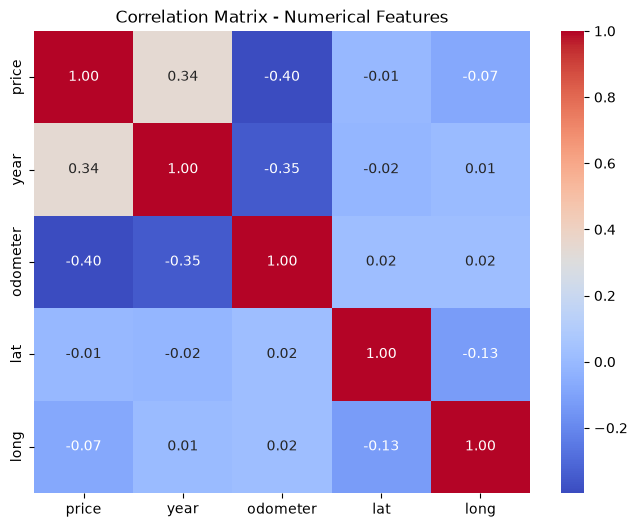

In [69]:
corr = df[
    ["price", "year", "odometer", "lat", "long"]
].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix - Numerical Features")
plt.show()

In [62]:
X = df.drop(columns=["price"])
y = df["price"]

print("X shape :", X.shape)
print("y shape :", y.shape)

X shape : (393932, 16)
y shape : (393932,)


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (315145, 16)
X_test  : (78787, 16)
y_train : (315145,)
y_test  : (78787,)


In [64]:
numeric_features = [
    "year",
    "odometer",
    "lat",
    "long"
]

categorical_features = [
    "region",
    "manufacturer",
    "model",
    "condition",
    "cylinders",
    "fuel",
    "title_status",
    "transmission",
    "drive",
    "type",
    "paint_color",
    "state"
]

Linear models

In [ ]:
numeric_transformer_linear = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)
categorical_transforme = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="unknown"
        )),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [71]:
preprocessor_linear = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_linear, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [73]:
linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_linear),
        ("model", LinearRegression())
    ]
)
linear_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [75]:
y_pred_linear = linear_pipeline.predict(X_test)

# Metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print(f"MAE  : ${mae_linear:,.2f}")
print(f"RMSE : ${rmse_linear:,.2f}")
print(f"R²   : {r2_linear:.4f}")

Linear Regression
-----------------
MAE  : $4,780.46
RMSE : $9,712.75
R²   : 0.6408


In [76]:
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_linear),
        ("model", Ridge(alpha=1.0))
    ]
)

ridge_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [77]:
y_pred_ridge = ridge_pipeline.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("----------------")
print(f"MAE  : ${mae_ridge:,.2f}")
print(f"RMSE : ${rmse_ridge:,.2f}")
print(f"R²   : {r2_ridge:.4f}")

Ridge Regression
----------------
MAE  : $4,893.69
RMSE : $9,665.71
R²   : 0.6443


In [78]:
lasso_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_linear),
        ("model", Lasso(alpha=1.0, max_iter=10000))
    ]
)

lasso_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [79]:
y_pred_lasso = lasso_pipeline.predict(X_test)

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("----------------")
print(f"MAE  : ${mae_lasso:,.2f}")
print(f"RMSE : ${rmse_lasso:,.2f}")
print(f"R²   : {r2_lasso:.4f}")

Lasso Regression
----------------
MAE  : $6,090.68
RMSE : $10,720.08
R²   : 0.5625


no linear models

In [80]:
numeric_transformer_rf = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_rf = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="unknown"
        )),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor_rf = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf, numeric_features),
        ("cat", categorical_transformer_rf, categorical_features)
    ]
)

In [84]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_rf),
        ("model", RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            min_samples_leaf=2,
            max_depth=20,
            n_jobs=2
        ))
    ]
)
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [85]:
y_pred_rf = rf_pipeline.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("-------------")
print(f"MAE  : ${mae_rf:,.2f}")
print(f"RMSE : ${rmse_rf:,.2f}")
print(f"R²   : {r2_rf:.4f}") 

Random Forest
-------------
MAE  : $3,802.45
RMSE : $7,551.23
R²   : 0.7829


In [86]:
y_pred_rf_train = rf_pipeline.predict(X_train)

mae_rf_train = mean_absolute_error(y_train, y_pred_rf_train)
rmse_rf_train = np.sqrt(mean_squared_error(y_train, y_pred_rf_train))
r2_rf_train = r2_score(y_train, y_pred_rf_train)

print("Random Forest - TRAIN")
print("---------------------")
print(f"MAE  : ${mae_rf_train:,.2f}")
print(f"RMSE : ${rmse_rf_train:,.2f}")
print(f"R²   : {r2_rf_train:.4f}")

print("\nRandom Forest - TEST")
print("--------------------")
print(f"MAE  : ${mae_rf:,.2f}")
print(f"RMSE : ${rmse_rf:,.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest - TRAIN
---------------------
MAE  : $3,337.74
RMSE : $6,569.76
R²   : 0.8376

Random Forest - TEST
--------------------
MAE  : $3,802.45
RMSE : $7,551.23
R²   : 0.7829


In [89]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [50, 75, 100],
    "model__max_depth": [15, 20, 25, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5, 0.8]
}
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=5,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

In [88]:
X_train_tune, _, y_train_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    random_state=42
)

print("X_train_tune :", X_train_tune.shape)
print("y_train_tune :", y_train_tune.shape)

X_train_tune : (50000, 16)
y_train_tune : (50000,)


In [90]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=5,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=2
)
rf_random_search.fit(X_train_tune, y_train_tune)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [15, 20, ...], 'model__max_features': ['sqrt', 0.5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [91]:
print("Best parameters:")
print(rf_random_search.best_params_)

print("\nBest CV MAE:")
print(-rf_random_search.best_score_)

Best parameters:
{'model__n_estimators': 50, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': 20}

Best CV MAE:
4442.751196721101


In [92]:
rf_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor_rf),
        ("model", RandomForestRegressor(
            n_estimators=50,
            max_depth=20,
            min_samples_split=10,
            min_samples_leaf=4,
            max_features=0.5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)
rf_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [93]:
y_pred_final = rf_final.predict(X_test)

mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

print("Random Forest - FINAL")
print("---------------------")
print(f"MAE  : ${mae_final:,.2f}")
print(f"RMSE : ${rmse_final:,.2f}")
print(f"R²   : {r2_final:.4f}")

Random Forest - FINAL
---------------------
MAE  : $3,687.52
RMSE : $8,198.79
R²   : 0.7441


In [95]:
from sklearn.preprocessing import OrdinalEncoder

categorical_transformer_hgb = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="unknown"
        )),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]
)

numeric_transformer_hgb = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

preprocessor_hgb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_hgb, numeric_features),
        ("cat", categorical_transformer_hgb, categorical_features)
    ]
)

In [97]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_hgb),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.1,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ))
    ]
)
hgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [98]:
y_pred_hgb = hgb_pipeline.predict(X_test)

mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))
r2_hgb = r2_score(y_test, y_pred_hgb)

print("HistGradientBoosting")
print("--------------------")
print(f"MAE  : ${mae_hgb:,.2f}")
print(f"RMSE : ${rmse_hgb:,.2f}")
print(f"R²   : {r2_hgb:.4f}")

HistGradientBoosting
--------------------
MAE  : $4,072.63
RMSE : $8,528.71
R²   : 0.7231


In [99]:
import xgboost

print(xgboost.__version__)

3.4.1


In [100]:
numeric_transformer_xgb = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_xgb = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="unknown"
        )),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

preprocessor_xgb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_xgb, numeric_features),
        ("cat", categorical_transformer_xgb, categorical_features)
    ]
)

In [101]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_xgb),
        ("model", XGBRegressor(
            n_estimators=300,
            max_depth=8,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]
)
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['region','year','manufacturer',...,'state','lat','long']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenate

In [102]:
y_pred_xgb = xgb_pipeline.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost")
print("-------")
print(f"MAE  : ${mae_xgb:,.2f}")
print(f"RMSE : ${rmse_xgb:,.2f}")
print(f"R²   : {r2_xgb:.4f}")

XGBoost
-------
MAE  : $4,351.77
RMSE : $8,128.68
R²   : 0.7484


In [104]:
import catboost

print(catboost.__version__)

1.2.10


In [105]:
from catboost import CatBoostRegressor

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# CatBoost nécessite que les colonnes catégorielles
# ne contiennent pas de NaN
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna("unknown").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("unknown").astype(str)

# Indices des colonnes catégorielles
cat_features_indices = [
    X_train_cb.columns.get_loc(col)
    for col in categorical_features
]


In [106]:
catboost_model = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=100,
    thread_count=-1
)
catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features_indices
)

0:	learn: 15922.5938058	total: 591ms	remaining: 4m 54s
100:	learn: 9649.2063440	total: 40.3s	remaining: 2m 39s
200:	learn: 9030.1901029	total: 1m 17s	remaining: 1m 55s
300:	learn: 8663.5736864	total: 1m 58s	remaining: 1m 18s
400:	learn: 8420.2731635	total: 2m 37s	remaining: 38.8s
499:	learn: 8239.7794801	total: 3m 17s	remaining: 0us


CatBoostRegressor(depth=8, iterations=500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [107]:
y_pred_cb = catboost_model.predict(X_test_cb)
mae_cb = mean_absolute_error(y_test, y_pred_cb)
rmse_cb = np.sqrt(mean_squared_error(y_test, y_pred_cb))
r2_cb = r2_score(y_test, y_pred_cb)

print("CatBoost")
print("--------")
print(f"MAE  : ${mae_cb:,.2f}")
print(f"RMSE : ${rmse_cb:,.2f}")
print(f"R²   : {r2_cb:.4f}")

CatBoost
--------
MAE  : $3,937.98
RMSE : $8,109.50
R²   : 0.7496


Feature engineering

In [109]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

X_train_fe["vehicle_age"] = 2021 - X_train_fe["year"]
X_test_fe["vehicle_age"] = 2021 - X_test_fe["year"]

In [110]:
X_train_fe["mileage_per_year"] = (
    X_train_fe["odometer"] / X_train_fe["vehicle_age"].replace(0, np.nan)
)

X_test_fe["mileage_per_year"] = (
    X_test_fe["odometer"] / X_test_fe["vehicle_age"].replace(0, np.nan)
)

In [111]:
print(X_train_fe[[
    "year",
    "odometer",
    "vehicle_age",
    "mileage_per_year"
]].head())

print("\nShape:")
print(X_train_fe.shape)

          year  odometer  vehicle_age  mileage_per_year
105717  2012.0   98549.0          9.0      10949.888889
401778  2008.0  111000.0         13.0       8538.461538
43626   2013.0  145499.0          8.0      18187.375000
200808  2013.0  161918.0          8.0      20239.750000
401427  2017.0   28564.0          4.0       7141.000000

Shape:
(315145, 18)


In [112]:
numeric_features_fe = [
    "year",
    "odometer",
    "lat",
    "long",
    "vehicle_age",
    "mileage_per_year"
]

In [113]:
categorical_features_fe = [
    "region",
    "manufacturer",
    "model",
    "condition",
    "cylinders",
    "fuel",
    "title_status",
    "transmission",
    "drive",
    "type",
    "paint_color",
    "state"
]
numeric_transformer_rf_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer_rf_fe = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="unknown"
        )),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor_rf_fe = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf_fe, numeric_features_fe),
        ("cat", categorical_transformer_rf_fe, categorical_features_fe)
    ]
)

In [117]:
rf_fe = Pipeline(
    steps=[
        ("preprocessor", preprocessor_rf_fe),
        ("model", RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            max_depth=20,
            min_samples_leaf=2,
            n_jobs=-1
        ))
    ]
)
rf_fe.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['region','year','manufacturer',...,'long','vehicle_age', 'mileage_per_year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [118]:
y_pred_rf_fe = rf_fe.predict(X_test_fe)

mae_rf_fe = mean_absolute_error(y_test, y_pred_rf_fe)
rmse_rf_fe = np.sqrt(mean_squared_error(y_test, y_pred_rf_fe))
r2_rf_fe = r2_score(y_test, y_pred_rf_fe)

print("Random Forest + Feature Engineering")
print("------------------------------------")
print(f"MAE  : ${mae_rf_fe:,.2f}")
print(f"RMSE : ${rmse_rf_fe:,.2f}")
print(f"R²   : {r2_rf_fe:.4f}")

Random Forest + Feature Engineering
------------------------------------
MAE  : $3,798.08
RMSE : $7,579.50
R²   : 0.7813
